# HW4.a (1, 2) + HW4.5 Parts A, B, D, E — single Colab notebook
**Runtime → Change runtime type → T4 GPU** first. Run top to bottom.
Part C (DDP) is skipped (optional) → write *Part C skipped (optional)* in METRICS.md.
Sections: **0** setup · **1** HW4.a-1 BERT fine-tune · **2** Part A batch scaling · **3** Part B memory techniques · **4** HW4.a-2 + Part D vLLM serving · **5** Part E KV cache · **6** GPU-hours.
Nothing here is pre-measured: every number comes from your run.

## 0. Setup

In [1]:
!nvidia-smi -L
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip -q install transformers scikit-learn pandas matplotlib bitsandbytes datasets
!mkdir -p /content/hw45/results

GPU 0: NVIDIA A100-SXM4-40GB (UUID: GPU-a7917fc8-eb36-56a0-5ead-9ce94cf71b01)
name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


**Dataset comes from Hugging Face** (no CSV needed). It must be the *same* dataset, split and rows as your HW4.a — set `HF_DATASET`, `HF_CONFIG`, `HF_SPLIT`, `SLICE`, columns and `SEED` in the next cell. Default below is `cardiffnlp/tweet_eval` / `sentiment` as a placeholder.

**Edit this cell with your HW4.a values** (same dataset, SLICE rows, SEED, 70/15/15 split, model, max_len, lr, epochs, batch size).

In [2]:
%%writefile /content/hw45/config.py
"""Shared settings. FILL IN the values marked TODO from your original HW4 code
so every run uses the exact same data slice, split and fine-tune recipe."""
import os

# Must be IDENTICAL to HW4.a: same Twitter sentiment data, same rows, same split, same SEED.
# ---- TODO: copy these from your HW4.a code -------------------------------
# Hugging Face source (used if HF_DATASET is set); otherwise falls back to the CSV at DATA_PATH
HF_DATASET = "cardiffnlp/tweet_eval"          # TODO e.g. "cardiffnlp/tweet_eval" -- MUST be the dataset you used in HW4.a
HF_CONFIG = "sentiment"           # TODO e.g. "sentiment"
HF_SPLIT = "train"         # TODO the split HW4.a sliced rows from
DATA_PATH = os.environ.get("HW4_DATA", "data/train.csv")  # CSV fallback
TEXT_COL = "text"          # TODO column holding the input text
LABEL_COL = "label"        # TODO column holding the class label
SLICE = (638, 5638)        # course SLICE=638 (6638 % 1000): 5,000 consecutive rows 638..5637
SEED = 6638                # course SEED (student ID last 4)
MODEL_NAME = "bert-base-uncased"  # TODO the BERT checkpoint used in HW4
MAX_LEN = 128              # TODO
LR = 2e-5                  # TODO
EPOCHS = 3                 # TODO
BASE_BATCH = 16            # TODO the HW4.a batch size (the reference run)
WEIGHT_DECAY = 0.01
# --------------------------------------------------------------------------

SPLIT = (0.70, 0.15, 0.15)  # train / val / test
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)


Writing /content/hw45/config.py


In [3]:
%%writefile /content/hw45/data.py
"""Data loading: fixed 5,000-row slice, seeded 70/15/15 split, tokenization."""
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

import config as C


class TextDS(Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item


def load_frame(smoke=False):
    if smoke:  # synthetic data so the pipeline can be tested without your CSV
        rng = np.random.RandomState(0)
        words = ["good", "bad", "ok", "fine", "poor", "great", "awful", "nice"]
        n = 300
        labels = rng.randint(0, 3, n)
        texts = [" ".join(rng.choice(words, 12)) + f" {l}" for l in labels]
        return pd.DataFrame({C.TEXT_COL: texts, C.LABEL_COL: labels})
    if C.HF_DATASET:
        from datasets import load_dataset
        df = load_dataset(C.HF_DATASET, C.HF_CONFIG, split=C.HF_SPLIT).to_pandas()
        src = f"{C.HF_DATASET}/{C.HF_CONFIG}/{C.HF_SPLIT}"
    else:
        df = pd.read_csv(C.DATA_PATH); src = C.DATA_PATH
    a, b = C.SLICE
    df = df.iloc[a:b].reset_index(drop=True)
    print(f"[data] using rows {a}..{b - 1} of {src} ({len(df)} rows)")
    return df


def split_frame(df):
    rng = np.random.RandomState(C.SEED)
    idx = rng.permutation(len(df))
    n_tr = int(C.SPLIT[0] * len(df))
    n_va = int(C.SPLIT[1] * len(df))
    parts = (idx[:n_tr], idx[n_tr:n_tr + n_va], idx[n_tr + n_va:])
    return [df.iloc[p].reset_index(drop=True) for p in parts]


def make_datasets(tokenizer, smoke=False):
    df = load_frame(smoke)
    tr, va, te = split_frame(df)
    classes = sorted(df[C.LABEL_COL].unique().tolist())
    cmap = {c: i for i, c in enumerate(classes)}

    def enc(d):
        e = tokenizer(d[C.TEXT_COL].astype(str).tolist(), truncation=True,
                      padding="max_length", max_length=C.MAX_LEN if not smoke else 32,
                      return_tensors="pt")
        y = torch.tensor(d[C.LABEL_COL].map(cmap).values, dtype=torch.long)
        return TextDS(e, y)

    return enc(tr), enc(va), enc(te), classes


Writing /content/hw45/data.py


In [4]:
%%writefile /content/hw45/train_bert.py
"""BERT fine-tune with the HW4.5 memory/throughput knobs.

Examples:
  python train_bert.py --tag baseline
  python train_bert.py --batch-size 64 --amp --tag amp64
  python train_bert.py --grad-ckpt --accum-steps 4 --optim adamw8bit --tag combo
  python train_bert.py --smoke --tag smoke        # CPU test, tiny random BERT
Writes results/<tag>.json. Exit code 3 + {"oom": true} JSON on CUDA OOM.
"""
import argparse, json, os, time

import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, BertConfig, BertForSequenceClassification, AutoModelForSequenceClassification

import config as C
from data import make_datasets


def get_args(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--batch-size", type=int, default=C.BASE_BATCH)
    p.add_argument("--epochs", type=int, default=C.EPOCHS)
    p.add_argument("--amp", action="store_true", help="mixed precision")
    p.add_argument("--amp-dtype", choices=["fp16", "bf16"], default="fp16")
    p.add_argument("--grad-ckpt", action="store_true")
    p.add_argument("--accum-steps", type=int, default=1)
    p.add_argument("--optim", choices=["adamw", "adamw8bit"], default="adamw")
    p.add_argument("--tag", default="run")
    p.add_argument("--smoke", action="store_true")
    p.add_argument("--max-train-steps", type=int, default=0, help="stop after N optimizer steps (for scaling probes)")
    p.add_argument("--no-eval", action="store_true", help="skip val/test (scaling probes)")
    p.add_argument("--out-dir", default=C.RESULTS_DIR)
    return p.parse_args(argv)


def build_model(num_labels, smoke):
    if smoke:
        cfg = BertConfig(hidden_size=64, num_hidden_layers=2, num_attention_heads=2,
                         intermediate_size=128, vocab_size=30522, num_labels=num_labels)
        return BertForSequenceClassification(cfg)
    return AutoModelForSequenceClassification.from_pretrained(C.MODEL_NAME, num_labels=num_labels)


def build_optimizer(model, kind):
    if kind == "adamw8bit":
        import bitsandbytes as bnb
        return bnb.optim.AdamW8bit(model.parameters(), lr=C.LR, weight_decay=C.WEIGHT_DECAY)
    return torch.optim.AdamW(model.parameters(), lr=C.LR, weight_decay=C.WEIGHT_DECAY)


@torch.no_grad()
def evaluate(model, loader, dev, amp_ctx):
    model.eval()
    tot, n, preds, ys = 0.0, 0, [], []
    for b in loader:
        b = {k: v.to(dev) for k, v in b.items()}
        with amp_ctx():
            out = model(**b)
        tot += out.loss.item() * len(b["labels"]); n += len(b["labels"])
        preds.append(out.logits.argmax(-1).cpu()); ys.append(b["labels"].cpu())
    p, y = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return tot / n, float((p == y).mean()), p, y


def main(argv=None):
    a = get_args(argv)
    torch.manual_seed(C.SEED); np.random.seed(C.SEED)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_cuda = dev.type == "cuda"
    tok = None if a.smoke else AutoTokenizer.from_pretrained(C.MODEL_NAME)
    if a.smoke:  # tiny fake tokenizer: hash words into vocab
        class FakeTok:
            def __call__(self, texts, truncation, padding, max_length, return_tensors):
                ids = torch.zeros(len(texts), max_length, dtype=torch.long)
                for i, t in enumerate(texts):
                    for j, w in enumerate(t.split()[:max_length]):
                        ids[i, j] = (hash(w) % 30000) + 1
                return {"input_ids": ids, "attention_mask": (ids > 0).long()}
        tok = FakeTok()

    tr, va, te, classes = make_datasets(tok, a.smoke)
    result = {"tag": a.tag, "args": vars(a), "device": str(dev), "n_train": len(tr),
              "n_val": len(va), "n_test": len(te), "classes": [str(c) for c in classes]}
    if use_cuda:
        result["gpu"] = torch.cuda.get_device_name(0)
        torch.cuda.reset_peak_memory_stats()

    try:
        model = build_model(len(classes), a.smoke).to(dev)
        if a.grad_ckpt:
            model.gradient_checkpointing_enable()
        opt = build_optimizer(model, a.optim)
        dtype = torch.bfloat16 if a.amp_dtype == "bf16" else torch.float16
        amp_on = a.amp and use_cuda
        use_scaler = amp_on and dtype == torch.float16
        scaler = torch.amp.GradScaler("cuda") if use_scaler else None
        amp_ctx = (lambda: torch.autocast("cuda", dtype=dtype)) if amp_on else (lambda: torch.autocast("cpu", enabled=False))

        tl = DataLoader(tr, batch_size=a.batch_size, shuffle=True, drop_last=True,
                        generator=torch.Generator().manual_seed(C.SEED))
        vl = DataLoader(va, batch_size=64); tel = DataLoader(te, batch_size=64)

        hist, best, best_state, steps = [], (-1, 0), None, 0
        t_start = time.time(); train_time = 0.0; samples = 0
        stop = False
        for ep in range(1, a.epochs + 1):
            model.train()
            if use_cuda: torch.cuda.synchronize()
            t0 = time.time(); run, cnt = 0.0, 0
            opt.zero_grad(set_to_none=True)
            for i, b in enumerate(tl, 1):
                b = {k: v.to(dev) for k, v in b.items()}
                with amp_ctx():
                    loss = model(**b).loss / a.accum_steps
                (scaler.scale(loss) if scaler else loss).backward()
                run += loss.item() * a.accum_steps * len(b["labels"]); cnt += len(b["labels"])
                samples += len(b["labels"])
                if i % a.accum_steps == 0:
                    if scaler:
                        scaler.step(opt); scaler.update()
                    else:
                        opt.step()
                    opt.zero_grad(set_to_none=True); steps += 1
                    if a.max_train_steps and steps >= a.max_train_steps:
                        stop = True; break
            if use_cuda: torch.cuda.synchronize()
            ep_time = time.time() - t0; train_time += ep_time
            rec = {"epoch": ep, "train_loss": run / max(cnt, 1), "epoch_time_s": ep_time,
                   "samples_per_s": cnt / ep_time}
            if not a.no_eval:
                vloss, vacc, _, _ = evaluate(model, vl, dev, amp_ctx)
                rec.update(val_loss=vloss, val_acc=vacc)
                if vacc > best[0]:
                    best = (vacc, ep)
            hist.append(rec); print(json.dumps(rec))
            if stop: break

        result.update(history=hist, train_time_s=train_time, wall_clock_s=time.time() - t_start,
                      samples_per_s=samples / train_time, optimizer_steps=steps,
                      effective_batch=a.batch_size * a.accum_steps)
        if use_cuda:
            result["peak_mem_mb"] = torch.cuda.max_memory_allocated() / 2**20
        if not a.no_eval:
            result["best_epoch"] = best[1]; result["best_val_acc"] = best[0]
            tloss, tacc, p, y = evaluate(model, tel, dev, amp_ctx)
            result.update(test_loss=tloss, test_acc=tacc)
            from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
            cm = confusion_matrix(y, p, labels=list(range(len(classes))))
            pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=list(range(len(classes))), zero_division=0)
            result["confusion_matrix"] = cm.tolist()
            result["per_class"] = [{"class": str(classes[i]), "precision": float(pr[i]), "recall": float(rc[i]),
                                    "f1": float(f1[i]), "support": int(sup[i])} for i in range(len(classes))]
            worst = int(np.argmin(f1)); result["worst_class"] = str(classes[worst])
            wrong = np.where((y == worst) & (p != y))[0][:5].tolist()
            texts = te_texts(a)
            result["misclassified_examples"] = [{"text": texts[j] if texts else f"test idx {j}",
                                                 "true": str(classes[int(y[j])]), "pred": str(classes[int(p[j])])}
                                                for j in wrong]
        result["oom"] = False
        code = 0
    except torch.cuda.OutOfMemoryError:
        result["oom"] = True; code = 3
        print("CUDA OOM")

    path = os.path.join(a.out_dir, f"{a.tag}.json")
    os.makedirs(a.out_dir, exist_ok=True)
    with open(path, "w") as f:
        json.dump(result, f, indent=2)
    print("wrote", path)
    return code


def te_texts(a):
    """Test-set raw texts (same split as data.py) for error analysis."""
    from data import load_frame, split_frame
    return split_frame(load_frame(a.smoke))[2][C.TEXT_COL].astype(str).tolist()


if __name__ == "__main__":
    raise SystemExit(main())


Writing /content/hw45/train_bert.py


In [5]:
%%writefile /content/hw45/batch_scaling.py
"""Part A: batch-size scaling until OOM. One subprocess per batch size so an
OOM never poisons the next run. Reports throughput, peak memory, time/epoch."""
import argparse, json, os, subprocess, sys

import config as C


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--start", type=int, default=8)
    p.add_argument("--max", type=int, default=4096)
    p.add_argument("--epochs", type=int, default=1)
    p.add_argument("--extra", default="", help='extra train_bert flags, e.g. "--amp"')
    p.add_argument("--prefix", default="scale")
    p.add_argument("--smoke", action="store_true")
    a = p.parse_args()

    rows, bs = [], a.start
    while bs <= a.max:
        tag = f"{a.prefix}_bs{bs}"
        cmd = [sys.executable, "train_bert.py", "--batch-size", str(bs), "--epochs", str(a.epochs),
               "--tag", tag, "--no-eval"] + a.extra.split() + (["--smoke"] if a.smoke else [])
        print(">>", " ".join(cmd), flush=True)
        rc = subprocess.run(cmd).returncode
        path = os.path.join(C.RESULTS_DIR, f"{tag}.json")
        r = json.load(open(path)) if os.path.exists(path) else {"oom": True}
        if rc != 0 or r.get("oom"):
            rows.append({"batch_size": bs, "oom": True}); print(f"OOM/failure at batch {bs}"); break
        rows.append({"batch_size": bs, "oom": False, "samples_per_s": r["samples_per_s"],
                     "peak_mem_mb": r.get("peak_mem_mb"), "time_per_epoch_s": r["train_time_s"] / a.epochs})
        bs *= 2

    out = os.path.join(C.RESULTS_DIR, f"{a.prefix}_summary.json")
    json.dump(rows, open(out, "w"), indent=2)
    print(f"\n{'batch':>6} {'samples/s':>10} {'peak MB':>9} {'s/epoch':>8}")
    for r in rows:
        print(f"{r['batch_size']:>6} " + ("OOM" if r["oom"] else
              f"{r['samples_per_s']:>10.1f} {r['peak_mem_mb'] or 0:>9.0f} {r['time_per_epoch_s']:>8.1f}"))

    ok = [r for r in rows if not r["oom"]]
    if ok:
        import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
        x = [r["batch_size"] for r in ok]
        ax[0].plot(x, [r["samples_per_s"] for r in ok], "o-"); ax[0].set_xscale("log", base=2)
        ax[0].set_xlabel("batch size"); ax[0].set_ylabel("samples/s"); ax[0].set_title("Throughput")
        ax[1].plot(x, [r["peak_mem_mb"] or 0 for r in ok], "o-"); ax[1].set_xscale("log", base=2)
        ax[1].set_xlabel("batch size"); ax[1].set_ylabel("peak MB"); ax[1].set_title("Peak GPU memory")
        fig.tight_layout(); fig.savefig(os.path.join(C.RESULTS_DIR, f"{a.prefix}_plot.png"), dpi=150)


if __name__ == "__main__":
    main()


Writing /content/hw45/batch_scaling.py


In [6]:
%%writefile /content/hw45/memory_techniques.py
"""Part B: each memory technique independently vs baseline, then the best
combination, then a ranking of memory saved per throughput lost.
Quality (val acc) is recorded too, so you can say whether it hurt."""
import argparse, json, os, subprocess, sys

import config as C

CONFIGS = {
    "baseline":   [],
    "amp":        ["--amp"],
    "grad_ckpt":  ["--grad-ckpt"],
    "accum4":     ["--accum-steps", "4"],       # use with batch-size/4 to keep effective batch (see --bs)
    "adamw8bit":  ["--optim", "adamw8bit"],
}


def run(tag, flags, bs, epochs, smoke):
    cmd = [sys.executable, "train_bert.py", "--tag", tag, "--batch-size", str(bs),
           "--epochs", str(epochs)] + flags + (["--smoke"] if smoke else [])
    print(">>", " ".join(cmd), flush=True)
    subprocess.run(cmd)
    path = os.path.join(C.RESULTS_DIR, f"{tag}.json")
    return json.load(open(path)) if os.path.exists(path) else {"oom": True}


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--bs", type=int, default=C.BASE_BATCH, help="per-step batch used for every run")
    p.add_argument("--epochs", type=int, default=C.EPOCHS)
    p.add_argument("--combo", default="amp,grad_ckpt,adamw8bit", help="comma list of techniques to combine")
    p.add_argument("--smoke", action="store_true")
    a = p.parse_args()

    res = {}
    for name, flags in CONFIGS.items():
        res[name] = run(f"memtech_{name}", flags, a.bs, a.epochs, a.smoke)
    combo_flags = []
    for n in a.combo.split(","):
        combo_flags += CONFIGS[n]
    res["combo"] = run("memtech_combo", combo_flags, a.bs, a.epochs, a.smoke)

    base = res["baseline"]
    rows = []
    for name, r in res.items():
        if r.get("oom"):
            rows.append({"name": name, "oom": True}); continue
        mem = r.get("peak_mem_mb")
        row = {"name": name, "oom": False, "peak_mem_mb": mem, "samples_per_s": r["samples_per_s"],
               "best_val_acc": r.get("best_val_acc"), "test_acc": r.get("test_acc")}
        if mem and base.get("peak_mem_mb"):
            row["mem_saved_mb"] = base["peak_mem_mb"] - mem
            row["mem_saved_pct"] = 100 * (base["peak_mem_mb"] - mem) / base["peak_mem_mb"]
        row["throughput_lost_pct"] = 100 * (base["samples_per_s"] - r["samples_per_s"]) / base["samples_per_s"]
        # memory saved (%) per throughput point lost; floor the loss so free wins don't divide by ~0
        if "mem_saved_pct" in row:
            row["saved_per_lost"] = row["mem_saved_pct"] / max(row["throughput_lost_pct"], 1.0)
        rows.append(row)

    json.dump(rows, open(os.path.join(C.RESULTS_DIR, "memtech_summary.json"), "w"), indent=2)
    print(f"\n{'config':<12} {'peakMB':>8} {'saved%':>7} {'samp/s':>8} {'lost%':>7} {'saved/lost':>10} {'val_acc':>8}")
    for r in sorted([x for x in rows if not x["oom"]], key=lambda x: -x.get("saved_per_lost", -1e9)):
        print(f"{r['name']:<12} {r['peak_mem_mb'] or 0:>8.0f} {r.get('mem_saved_pct', 0):>7.1f} "
              f"{r['samples_per_s']:>8.1f} {r['throughput_lost_pct']:>7.1f} {r.get('saved_per_lost', 0):>10.2f} "
              f"{(r['best_val_acc'] or 0):>8.3f}")


if __name__ == "__main__":
    main()


Writing /content/hw45/memory_techniques.py


In [7]:
%%writefile /content/hw45/gpu_hours.py
"""GPU-hours calculator from your measured numbers.
  python gpu_hours.py --samples-per-s 210 --dataset-size 3500 --epochs 3 --n-gpus 1 --runs 10 --price 1.10
wall hours = dataset_size x epochs / samples_per_s / 3600 x runs   (samples_per_s is the global rate)
GPU-hours  = wall hours x n_gpus
"""
import argparse

p = argparse.ArgumentParser()
p.add_argument("--samples-per-s", type=float, required=True, help="measured GLOBAL samples/s")
p.add_argument("--dataset-size", type=int, required=True)
p.add_argument("--epochs", type=int, required=True)
p.add_argument("--n-gpus", type=int, default=1)
p.add_argument("--runs", type=int, default=1, help="e.g. hyperparameter sweep size")
p.add_argument("--price", type=float, default=None, help="$ per GPU-hour (optional)")
a = p.parse_args()

wall_h = a.dataset_size * a.epochs / a.samples_per_s / 3600 * a.runs
gpu_h = wall_h * a.n_gpus
print(f"wall-clock: {wall_h:.3f} h   GPU-hours: {gpu_h:.3f}")
if a.price: print(f"cost: ${gpu_h * a.price:.2f} at ${a.price}/GPU-h")


Writing /content/hw45/gpu_hours.py


In [8]:
%cd /content/hw45

/content/hw45


## 1. HW4.a-1 — BERT fine-tune baseline
Prints the exact row range used — copy it into METRICS.md.

In [9]:
!python train_bert.py --tag baseline

config.json: 100% 570/570 [00:00<00:00, 2.33MB/s]
tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 246kB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 9.36MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 13.5MB/s]
README.md: 100% 23.9k/23.9k [00:00<00:00, 48.2MB/s]

sentiment/train-00000-of-00001.parquet: downloading bytes:  44% 1.68M/3.78M [00:00<00:00, 2.29MB/s]
sentiment/train-00000-of-00001.parquet: downloading bytes: 100% 3.77M/3.77M [00:00<00:00, 4.06MB/s,  366kB/s  ]
sentiment/train-00000-of-00001.parquet: reconstructing file: 100% 3.78M/3.78M [00:00<00:00, 4.07MB/s,  368kB/s  ]

sentiment/test-00000-of-00001.parquet: downloading bytes:   0% 0.00/901k [00:00<?, ?B/s]
sentiment/test-00000-of-00001.parquet: downloading bytes: 100% 898k/898k [00:00<00:00, 1.76MB/s, 88.2kB/s  ]
sentiment/test-00000-of-00001.parquet: reconstructing file: 100% 901k/901k [00:00<00:00, 1.77MB/s, 88.8kB/s  ]

sentiment/validation-00000-of-00001.parq(…): downloading bytes:   0% 0.00/167k [00:00<?, ?B/s]

In [10]:
import json; r=json.load(open('results/baseline.json'))
for h in r['history']: print(h)
print({k:r[k] for k in ['best_epoch','test_acc','peak_mem_mb','train_time_s','wall_clock_s','worst_class']})
print(r['confusion_matrix']); print(r['per_class']); print(r['misclassified_examples'])

{'epoch': 1, 'train_loss': 0.858007587424112, 'epoch_time_s': 19.210264682769775, 'samples_per_s': 181.5695961299526, 'val_loss': 0.7422536301612854, 'val_acc': 0.6693333333333333}
{'epoch': 2, 'train_loss': 0.5815117357794298, 'epoch_time_s': 17.911666870117188, 'samples_per_s': 194.73341176410455, 'val_loss': 0.7431820475260417, 'val_acc': 0.684}
{'epoch': 3, 'train_loss': 0.3300972092349868, 'epoch_time_s': 17.900977849960327, 'samples_per_s': 194.84969085125874, 'val_loss': 0.9166138509114583, 'val_acc': 0.648}
{'best_epoch': 2, 'test_acc': 0.7, 'peak_mem_mb': 2537.2705078125, 'train_time_s': 55.02290940284729, 'wall_clock_s': 58.21712040901184, 'worst_class': '0'}
[[80, 43, 8], [33, 253, 46], [8, 87, 192]]
[{'class': '0', 'precision': 0.6611570247933884, 'recall': 0.6106870229007634, 'f1': 0.6349206349206349, 'support': 131}, {'class': '1', 'precision': 0.660574412532637, 'recall': 0.7620481927710844, 'f1': 0.7076923076923077, 'support': 332}, {'class': '2', 'precision': 0.7804878

## 2. Part A — Batch-size scaling until OOM

In [11]:
!python batch_scaling.py --start 8 --max 4096

>> /usr/bin/python3 train_bert.py --batch-size 8 --epochs 1 --tag scale_bs8 --no-eval
[data] using rows 638..5637 of cardiffnlp/tweet_eval/sentiment/train (5000 rows)
Loading weights: 100% 199/199 [00:00<00:00, 4213.47it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when load

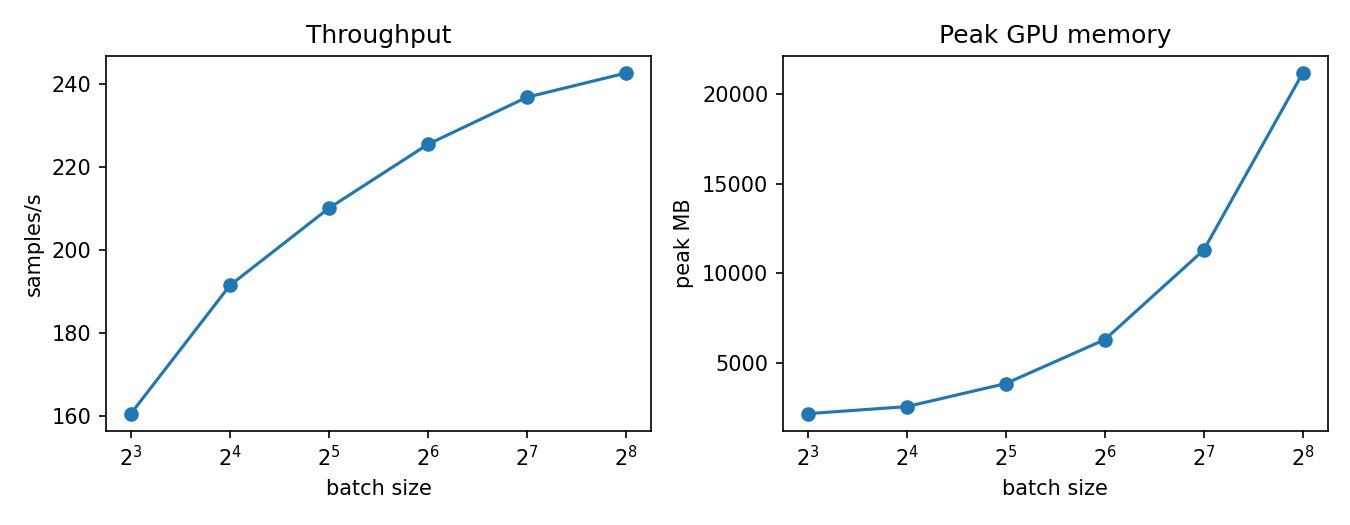

In [12]:
from IPython.display import Image; Image('results/scale_plot.png')

## 3. Part B — Memory techniques (each alone, then best combo, then ranking)

In [13]:
!python memory_techniques.py

>> /usr/bin/python3 train_bert.py --tag memtech_baseline --batch-size 16 --epochs 3
[data] using rows 638..5637 of cardiffnlp/tweet_eval/sentiment/train (5000 rows)
Loading weights: 100% 199/199 [00:00<00:00, 5797.74it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loadin

## 4. HW4.a-2 + Part D — HF batch 1 vs vLLM batch 1/8/32
vLLM install can replace Colab's torch. If imports fail afterwards, **Runtime → Restart session**, then re-run only from the `%cd` cell and this section (files in /content persist).

In [14]:
!pip -q install vllm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.


In [15]:
%%writefile /content/hw45/vllm_bench.py
"""Part D: HF generate (batch 1) vs vLLM offline engine (batch 1/8/32).
Reports tokens/s per request, p50/p95 per-request latency, total throughput.

  python vllm_bench.py --model Qwen/Qwen2.5-1.5B-Instruct --max-new 128 --n-prompts 64
Run HF and vLLM in separate processes (default does both: --engine hf|vllm|both)
because vLLM wants to reserve most of the GPU; "both" runs HF via subprocess first.
"""
import argparse, json, os, subprocess, sys, time

import numpy as np

import config as C

PROMPTS = [
    "Explain how gradient checkpointing reduces memory in neural network training.",
    "Write a short story about a robot learning to paint.",
    "Summarize the main causes of the French Revolution.",
    "What are the trade-offs between data parallelism and model parallelism?",
]


def prompts(n):
    return [PROMPTS[i % len(PROMPTS)] + f" (variant {i})" for i in range(n)]


def stats(lat, toks, wall):
    lat = np.array(lat)
    return {"p50_latency_s": float(np.percentile(lat, 50)), "p95_latency_s": float(np.percentile(lat, 95)),
            "tokens_per_s_per_request": float(np.mean(np.array(toks) / lat)),
            "total_tokens": int(sum(toks)), "wall_s": wall, "total_tokens_per_s": sum(toks) / wall}


def run_hf(a):
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(a.model)
    m = AutoModelForCausalLM.from_pretrained(a.model, torch_dtype=torch.float16).cuda().eval()
    ps = prompts(a.n_prompts); lat, toks = [], []
    with torch.no_grad():  # warmup
        m.generate(**tok(ps[0], return_tensors="pt").to("cuda"), max_new_tokens=8, do_sample=False)
    torch.cuda.synchronize(); w0 = time.time()
    for p in ps:
        enc = tok(p, return_tensors="pt").to("cuda")
        torch.cuda.synchronize(); t0 = time.time()
        with torch.no_grad():
            out = m.generate(**enc, max_new_tokens=a.max_new, min_new_tokens=a.max_new, do_sample=False)
        torch.cuda.synchronize(); lat.append(time.time() - t0)
        toks.append(out.shape[1] - enc["input_ids"].shape[1])
    res = {"hf_batch1": stats(lat, toks, time.time() - w0)}
    res["hf_batch1"]["peak_mem_mb"] = torch.cuda.max_memory_allocated() / 2**20
    return res


def run_vllm(a):
    from vllm import LLM, SamplingParams
    llm = LLM(model=a.model, dtype="float16", gpu_memory_utilization=a.gpu_util, max_model_len=a.max_model_len)
    sp = SamplingParams(temperature=0.0, max_tokens=a.max_new, min_tokens=a.max_new)
    ps = prompts(a.n_prompts)
    llm.generate(ps[:2], sp)  # warmup
    res = {}
    for bs in a.batches:
        lat, toks = [], []; w0 = time.time()
        for i in range(0, len(ps), bs):
            chunk = ps[i:i + bs]
            t0 = time.time(); outs = llm.generate(chunk, sp, use_tqdm=False); dt = time.time() - t0
            for o in outs:
                lat.append(dt); toks.append(len(o.outputs[0].token_ids))  # request latency = batch latency (offline API)
        res[f"vllm_batch{bs}"] = stats(lat, toks, time.time() - w0)
    return res


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--model", default="Qwen/Qwen2.5-1.5B-Instruct")
    p.add_argument("--engine", choices=["hf", "vllm", "both"], default="both")
    p.add_argument("--max-new", type=int, default=128)
    p.add_argument("--n-prompts", type=int, default=64)
    p.add_argument("--batches", type=int, nargs="+", default=[1, 8, 32])
    p.add_argument("--gpu-util", type=float, default=0.85)
    p.add_argument("--max-model-len", type=int, default=2048)
    p.add_argument("--out", default=None)
    a = p.parse_args()

    if a.engine == "both":
        for eng in ("hf", "vllm"):
            subprocess.run([sys.executable, __file__] + [x for x in sys.argv[1:] if x not in ("both",)] +
                           ["--engine", eng, "--out", os.path.join(C.RESULTS_DIR, f"serving_{eng}.json")], check=False)
        r = {}
        for eng in ("hf", "vllm"):
            f = os.path.join(C.RESULTS_DIR, f"serving_{eng}.json")
            if os.path.exists(f): r.update(json.load(open(f)))
    else:
        r = run_hf(a) if a.engine == "hf" else run_vllm(a)
        if a.out: json.dump(r, open(a.out, "w"), indent=2)

    if a.engine == "both":
        json.dump(r, open(os.path.join(C.RESULTS_DIR, "serving_summary.json"), "w"), indent=2)
    print(f"\n{'config':<14} {'p50 s':>7} {'p95 s':>7} {'tok/s/req':>10} {'total tok/s':>12}")
    for k, v in r.items():
        print(f"{k:<14} {v['p50_latency_s']:>7.2f} {v['p95_latency_s']:>7.2f} "
              f"{v['tokens_per_s_per_request']:>10.1f} {v['total_tokens_per_s']:>12.1f}")


if __name__ == "__main__":
    main()


Writing /content/hw45/vllm_bench.py


In [16]:
%%writefile /content/hw45/kv_cache.py
"""Part E: KV-cache memory.
 theory:  python kv_cache.py theory --model Qwen/Qwen2.5-1.5B-Instruct --batch 8 --tokens 2048
 empirical (GPU): python kv_cache.py probe --model ... --batch 8
   Doubles context length until vLLM fails to start/generate (OOM or insufficient KV blocks),
   then binary-searches, reporting the longest working prompt+output length at that batch.
Formula: KV bytes = 2 (K and V) x layers x kv_heads x head_dim x dtype_bytes x tokens x batch.
"""
import argparse, json, os, subprocess, sys

import config as C


def kv_bytes(layers, kv_heads, head_dim, dtype_bytes, tokens, batch):
    return 2 * layers * kv_heads * head_dim * dtype_bytes * tokens * batch


def model_dims(name):
    from transformers import AutoConfig
    c = AutoConfig.from_pretrained(name)
    heads = c.num_attention_heads
    return dict(layers=c.num_hidden_layers, kv_heads=getattr(c, "num_key_value_heads", heads),
                head_dim=getattr(c, "head_dim", None) or c.hidden_size // heads)


def theory(a):
    d = model_dims(a.model)
    per_tok = kv_bytes(d["layers"], d["kv_heads"], d["head_dim"], a.dtype_bytes, 1, 1)
    tot = kv_bytes(d["layers"], d["kv_heads"], d["head_dim"], a.dtype_bytes, a.tokens, a.batch)
    r = {**d, "dtype_bytes": a.dtype_bytes, "bytes_per_token": per_tok, "batch": a.batch,
         "tokens": a.tokens, "total_gb": tot / 2**30}
    print(json.dumps(r, indent=2))
    json.dump(r, open(os.path.join(C.RESULTS_DIR, "kv_theory.json"), "w"), indent=2)


def try_len(a, length):
    """One attempt in a fresh process (an OOM can't be recovered in-process)."""
    code = f"""
from vllm import LLM, SamplingParams
llm = LLM(model={a.model!r}, dtype='float16', gpu_memory_utilization={a.gpu_util}, max_model_len={length})
n_in = {length} - 16
prompts = [[100 + (i % 50)] * n_in for i in range({a.batch})]
sp = SamplingParams(temperature=0.0, max_tokens=16, min_tokens=16)
outs = llm.generate([{{'prompt_token_ids': p}} for p in prompts], sp, use_tqdm=False)
assert len(outs) == {a.batch}
"""
    return subprocess.run([sys.executable, "-c", code], capture_output=True).returncode == 0


def probe(a):
    lo, hi, L = 0, None, a.start
    while L <= a.max_len:
        ok = try_len(a, L); print(f"len {L}: {'ok' if ok else 'FAIL'}", flush=True)
        if ok: lo = L; L *= 2
        else: hi = L; break
    if hi:
        while hi - lo > max(64, lo // 32):
            mid = (lo + hi) // 2
            if try_len(a, mid): lo = mid
            else: hi = mid
    r = {"model": a.model, "batch": a.batch, "gpu_util": a.gpu_util, "longest_ok_tokens": lo}
    print(json.dumps(r))
    json.dump(r, open(os.path.join(C.RESULTS_DIR, "kv_probe.json"), "w"), indent=2)


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("mode", choices=["theory", "probe"])
    p.add_argument("--model", default="Qwen/Qwen2.5-1.5B-Instruct")
    p.add_argument("--batch", type=int, default=8)
    p.add_argument("--tokens", type=int, default=2048)
    p.add_argument("--dtype-bytes", type=int, default=2)
    p.add_argument("--gpu-util", type=float, default=0.85)
    p.add_argument("--start", type=int, default=1024)
    p.add_argument("--max-len", type=int, default=262144)
    a = p.parse_args()
    theory(a) if a.mode == "theory" else probe(a)


Writing /content/hw45/kv_cache.py


In [17]:
%cd /content/hw45
!python vllm_bench.py --model Qwen/Qwen2.5-0.5B-Instruct --max-new 128 --n-prompts 64 --gpu-util 0.80 --max-model-len 2048

/content/hw45
config.json: 100% 659/659 [00:00<00:00, 3.40MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 24.7MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 48.9MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 114MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 125MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

model.safetensors: downloading bytes:   3% 30.0M/988M [00:00<00:13, 73.6MB/s,  271kB/s  ]
model.safetensors: downloading bytes:  85% 843M/988M [00:01<00:00, 697MB/s, 70.0MB/s  ]
model.safetensors: reconstructing file:   8% 83.9M/988M [00:01<00:18, 48.0MB/s, 1.66MB/s  ]
model.safetensors: downloading bytes: 100% 854M/854M [00:02<00:00, 318MB/s, 77.8MB/s  ]
model.safetensors: reconstructing file: 100% 988M/988M [00:02<00:00, 368MB/s, 91.8MB/s  ]
Loading weights: 100% 290/290 [00:00<00:00, 1788.16it/s]
generation_config.json: 100% 242/242 [00:00<00:00, 1.30MB/s]

config           p50 s   p95 s  tok/s/req  total tok/s
hf_batch1         3.62 

## 5. Part E — KV cache: theory vs empirical (batch 8)

In [18]:
!python kv_cache.py theory --model Qwen/Qwen2.5-0.5B-Instruct --batch 8 --tokens 2048
!python kv_cache.py probe --model Qwen/Qwen2.5-0.5B-Instruct --batch 8 --gpu-util 0.80 --start 1024

{
  "layers": 24,
  "kv_heads": 2,
  "head_dim": 64,
  "dtype_bytes": 2,
  "bytes_per_token": 12288,
  "batch": 8,
  "tokens": 2048,
  "total_gb": 0.1875
}
len 1024: ok
len 2048: ok
len 4096: ok
len 8192: ok
len 16384: ok
len 32768: ok
len 65536: FAIL
{"model": "Qwen/Qwen2.5-0.5B-Instruct", "batch": 8, "gpu_util": 0.8, "longest_ok_tokens": 32768}


## 6. GPU-hours (uses samples/s from the baseline run)

In [19]:
import json
sps = json.load(open('results/baseline.json'))['samples_per_s']
!python gpu_hours.py --samples-per-s {sps} --dataset-size 3500 --epochs 3 --runs 1

wall-clock: 0.015 h   GPU-hours: 0.015


## Save results
Download `results/` and copy numbers into METRICS.md (include the `nvidia-smi -L` output from section 0).

In [20]:
!zip -rq /content/results.zip results
from google.colab import files; files.download('/content/results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>